Import packages and define cosmetic functions<br>
=================================================================================================

In [1]:
import os
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
import matplotlib.gridspec as gs
import math
import uproot
from matplotlib.ticker import AutoMinorLocator

def style( ax ):
    ax.grid(which='major', axis='x', linewidth=0.2, linestyle='-', color='0.75')
    ax.grid(which='major', axis='y', linewidth=0.2, linestyle='-', color='0.75')
    ax.tick_params(which='major', length=8)
    ax.tick_params(which='minor', length=4)
    #ax.xaxis.set_minor_locator(AutoMinorLocator())
    #ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.spines['bottom'].set_linewidth(1)
    ax.spines['top'].set_linewidth(1)
    ax.spines['left'].set_linewidth(1)
    ax.spines['right'].set_linewidth(1)
    ax.margins(x=0)
    ax.legend(numpoints=1, ncol=1, prop={'size': 10.5}, frameon=False, loc='upper right')

def labels( ax, xlabel=None, ylabel=None ):
    if xlabel is not None:
        ax.set_xlabel(xlabel, size=14, horizontalalignment='right', x=1.0)
    if ylabel is not None:
        ax.set_ylabel(ylabel, size=14, horizontalalignment='right', y=1.0)

Read files and save information in dataframes<br>
=================================================================================================

In [2]:
# Abertura dos arquivos reais localizados em projeto_final para o canal e±μ±
Data_MuonEG_G_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/Data_MuonEG_G_1_16_files_0_28/Tree.root")
Data_MuonEG_H_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/Data_MuonEG_H_1_16_files_0_18/Tree.root")

DYJetsToLL_PtZ_3To50_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-3To50_1_16_files_0_124/Tree.root")
DYJetsToLL_PtZ_50To100_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-50To100_1_16_files_0_89/Tree.root")
DYJetsToLL_PtZ_100To250_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-100To250_1_16_files_0_75/Tree.root")
DYJetsToLL_PtZ_250To400_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-250To400_1_16_files_0_46/Tree.root")
DYJetsToLL_PtZ_400To650_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-400To650_1_16_files_0_17/Tree.root")
DYJetsToLL_PtZ_650ToInf_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/DYJetsToLL_PtZ-650ToInf_1_16_files_0_16/Tree.root")

TTTo2L2Nu_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/TTTo2L2Nu_1_16_files_0_48/Tree.root")
WWTo2L2Nu_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/WWTo2L2Nu_1_16_files_0_6/Tree.root")
ZZTo2L2Nu_file = uproot.open("/sharedarea/AnaliseDeDados2026/projeto_final/ZZTo2L2Nu_1_16_files_0_14/Tree.root")

# Carregamento dos dados em formato de dicionário de DataFrames Pandas
ds = {}
ds["Data_MuonEG_G"] = Data_MuonEG_G_file["selection"].arrays(library="pd")
ds["Data_MuonEG_H"] = Data_MuonEG_H_file["selection"].arrays(library="pd")

ds["DYJetsToLL_PtZ_3To50"] = DYJetsToLL_PtZ_3To50_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_50To100"] = DYJetsToLL_PtZ_50To100_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_100To250"] = DYJetsToLL_PtZ_100To250_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_250To400"] = DYJetsToLL_PtZ_250To400_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_400To650"] = DYJetsToLL_PtZ_400To650_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_650ToInf"] = DYJetsToLL_PtZ_650ToInf_file["selection"].arrays(library="pd")

ds["TTTo2L2Nu"] = TTTo2L2Nu_file["selection"].arrays(library="pd")
ds["WWTo2L2Nu"] = WWTo2L2Nu_file["selection"].arrays(library="pd")
ds["ZZTo2L2Nu"] = ZZTo2L2Nu_file["selection"].arrays(library="pd")

Metadata and luminosity weight<br>
=================================================================================================

In [3]:
Data_luminosity = 16393.3805 # pb-¹

md = {} #                         [Cross section [pb], Generator weights sum]
md["DYJetsToLL_PtZ_3To50"] =    [1414,      123866571129.0938]
md["DYJetsToLL_PtZ_50To100"] =  [378.97,    46921372350.48828]
md["DYJetsToLL_PtZ_100To250"] = [93.1366,   6025316696.791992]
md["DYJetsToLL_PtZ_250To400"] = [3.7093,    152821361.0812912]
md["DYJetsToLL_PtZ_400To650"] = [0.515,     3369752.256501198]
md["DYJetsToLL_PtZ_650ToInf"] = [0.048934,  332449.5045676231]
md["TTTo2L2Nu"] =               [88.51,     721135180.715332]
md["WWTo2L2Nu"] =               [11.09,     32147079.16720963]
md["ZZTo2L2Nu"] =               [1.07118,   9737381.869026184]

# Cálculo do peso de evento para normalização à luminosidade dos dados
for process in ds.keys(): 
    if process[:4] != "Data":
        ds[process]["evtWeight"] = ds[process]["genWeight"] * (md[process][0] * Data_luminosity / md[process][1])

# Agrupamento dos datasets por tipo de processo físico
ds["Data"] = pd.concat([ds["Data_MuonEG_G"], ds["Data_MuonEG_H"]]).reset_index(drop=True)
del ds["Data_MuonEG_G"], ds["Data_MuonEG_H"]

ds["DYJetsToLL"] = pd.concat([
    ds["DYJetsToLL_PtZ_3To50"], ds["DYJetsToLL_PtZ_50To100"], 
    ds["DYJetsToLL_PtZ_100To250"], ds["DYJetsToLL_PtZ_250To400"], 
    ds["DYJetsToLL_PtZ_400To650"], ds["DYJetsToLL_PtZ_650ToInf"]
]).reset_index(drop=True)
del ds["DYJetsToLL_PtZ_3To50"], ds["DYJetsToLL_PtZ_50To100"], ds["DYJetsToLL_PtZ_100To250"], ds["DYJetsToLL_PtZ_250To400"], ds["DYJetsToLL_PtZ_400To650"], ds["DYJetsToLL_PtZ_650ToInf"]

ds["TT"] = ds["TTTo2L2Nu"].copy()
del ds["TTTo2L2Nu"]

ds["VV"] = pd.concat([ds["WWTo2L2Nu"], ds["ZZTo2L2Nu"]]).reset_index(drop=True)
del ds["WWTo2L2Nu"], ds["ZZTo2L2Nu"]

Check trigger efficiency plots<br>
=================================================================================================

/tmp/ipykernel_4211/3923944257.py:41: RuntimeWarning: invalid value encountered in divide
  TT_efficiency = np.array(TT_numerator)/np.array(TT_denominator)
/tmp/ipykernel_4211/3923944257.py:45: RuntimeWarning: invalid value encountered in divide
  Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
/tmp/ipykernel_4211/3923944257.py:82: RuntimeWarning: invalid value encountered in divide
  TT_efficiency = np.array(TT_numerator)/np.array(TT_denominator)
/tmp/ipykernel_4211/3923944257.py:85: RuntimeWarning: invalid value encountered in divide
  Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)


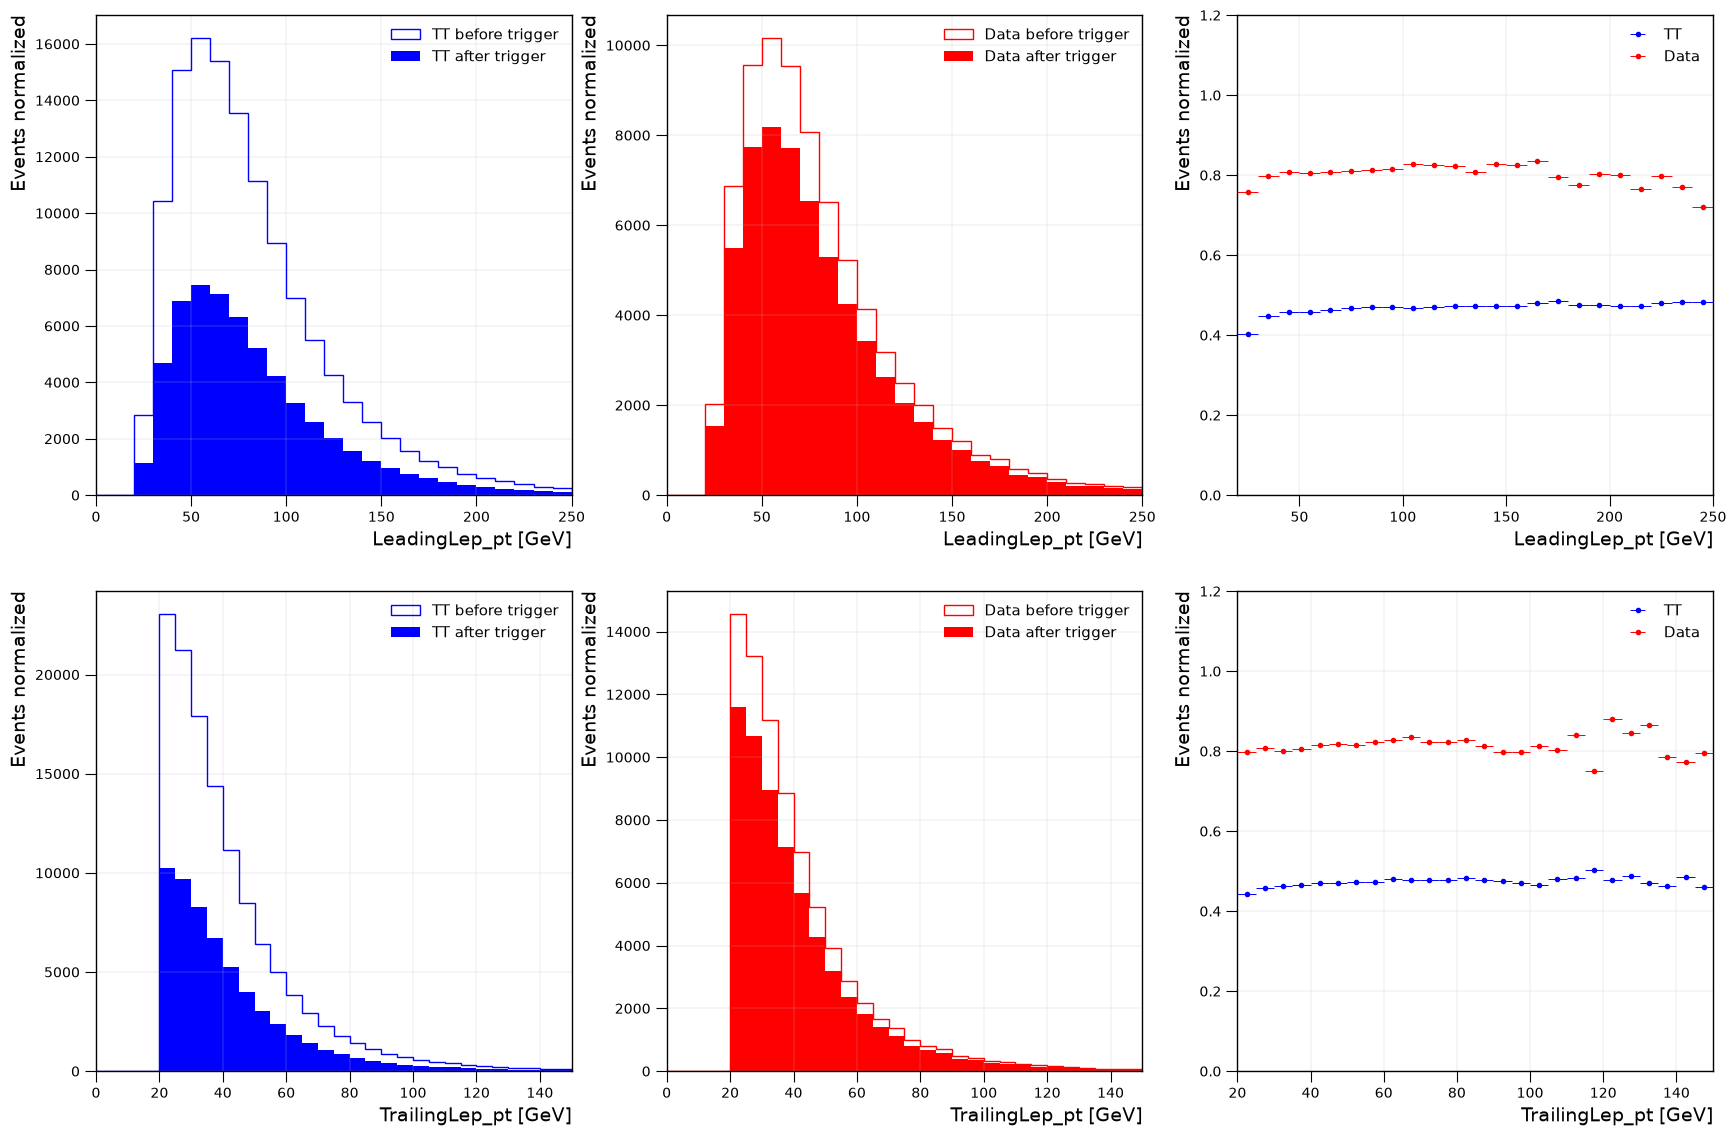

In [4]:
# Cria uma figura grande dividida em uma grade de 2 linhas por 3 colunas
fig1 = plt.figure(figsize=(21,12))
grid = [2, 3]
gs1 = gs.GridSpec(grid[0], grid[1])

# ==================================================================================================
# LINHA 1: ANÁLISE DO LÉPTON PRINCIPAL (LeadingLep_pt)
# ==================================================================================================

# 1. Painel esquerdo: Simulação (TT) - Antes e Depois do Trigger para o LeadingLep_pt
ax1 = plt.subplot(gs1[0])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
# Denominador: Todos os eventos de TT (antes do trigger)
TT_denominator, b_dummy, p_dummy = plt.hist(ds["TT"][var], bins=bins, weights=ds["TT"]["evtWeight"], color='blue', histtype='step', label="TT before trigger")
# Numerador: Apenas os eventos de TT que passaram pelo gatilho HLT_EleMu
TT_numerator, b_dummy, p_dummy = plt.hist(ds["TT"][ds["TT"]["HLT_EleMu"]][var], bins=bins, weights=ds["TT"][ds["TT"]["HLT_EleMu"]]["evtWeight"], color='blue', histtype='stepfilled', label="TT after trigger")
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# 2. Painel central: Dados Reais (Data) - Antes e Depois do Trigger para o LeadingLep_pt
ax1 = plt.subplot(gs1[1])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
# Denominador: Todos os eventos reais coletados
Data_denominator, b_dummy, p_dummy = plt.hist(ds["Data"][var], bins=bins, weights=ds["Data"]["evtWeight"], color='red', histtype='step', label="Data before trigger")
# Numerador: Apenas os eventos reais que ativaram o HLT_EleMu
Data_numerator, b_dummy, p_dummy = plt.hist(ds["Data"][ds["Data"]["HLT_EleMu"]][var], bins=bins, weights=ds["Data"][ds["Data"]["HLT_EleMu"]]["evtWeight"], color='red', histtype='stepfilled', label="Data after trigger")
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# 3. Painel direito: Curva de Eficiência do Trigger para o LeadingLep_pt (Data vs TT)
ax1 = plt.subplot(gs1[2])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx

# Calcula a eficiência dividindo o numerador pelo denominador para TT e plota com barras de erro
TT_efficiency = np.array(TT_numerator)/np.array(TT_denominator)
ax1.errorbar(x_mean, TT_efficiency, xerr=0.5*dx, fmt='.', ecolor='blue', color='blue', elinewidth=0.7, capsize=0, label="TT")

# Calcula a eficiência para os Dados Reais e plota comparativamente
Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
ax1.errorbar(x_mean, Data_efficiency, xerr=0.5*dx, fmt='.', ecolor='red', color='red', elinewidth=0.7, capsize=0, label="Data")

plt.ylim(0, 1.2)
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events normalized")

# ==================================================================================================
# LINHA 2: ANÁLISE DO LÉPTON SECUNDÁRIO (TrailingLep_pt)
# ==================================================================================================

# 4. Painel esquerdo inferior: Simulação (TT) - Antes e Depois do Trigger para o TrailingLep_pt
ax1 = plt.subplot(gs1[3])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
TT_denominator, b_dummy, p_dummy = plt.hist(ds["TT"][var], bins=bins, weights=ds["TT"]["evtWeight"], color='blue', histtype='step', label="TT before trigger")
TT_numerator, b_dummy, p_dummy = plt.hist(ds["TT"][ds["TT"]["HLT_EleMu"]][var], bins=bins, weights=ds["TT"][ds["TT"]["HLT_EleMu"]]["evtWeight"], color='blue', histtype='stepfilled', label="TT after trigger")
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# 5. Painel central inferior: Dados Reais (Data) - Antes e Depois do Trigger para o TrailingLep_pt
ax1 = plt.subplot(gs1[4])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
Data_denominator, b_dummy, p_dummy = plt.hist(ds["Data"][var], bins=bins, weights=ds["Data"]["evtWeight"], color='red', histtype='step', label="Data before trigger")
Data_numerator, b_dummy, p_dummy = plt.hist(ds["Data"][ds["Data"]["HLT_EleMu"]][var], bins=bins, weights=ds["Data"][ds["Data"]["HLT_EleMu"]]["evtWeight"], color='red', histtype='stepfilled', label="Data after trigger")
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# 6. Painel direito inferior: Curva de Eficiência do Trigger para o TrailingLep_pt (Data vs TT)
ax1 = plt.subplot(gs1[5])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx

TT_efficiency = np.array(TT_numerator)/np.array(TT_denominator)
ax1.errorbar(x_mean, TT_efficiency, xerr=0.5*dx, fmt='.', ecolor='blue', color='blue', elinewidth=0.7, capsize=0, label="TT")

Data_efficiency = np.array(Data_numerator)/np.array(Data_denominator)
ax1.errorbar(x_mean, Data_efficiency, xerr=0.5*dx, fmt='.', ecolor='red', color='red', elinewidth=0.7, capsize=0, label="Data")

plt.ylim(0, 1.2)
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events normalized")

# ==================================================================================================
# AJUSTES FINAIS E SALVAMENTO
# ==================================================================================================
plt.subplots_adjust(left=0.2, bottom=0.085, right=0.97, top=0.965, wspace=0.2, hspace=0.2)
plt.savefig('efficiency_plots.pdf')
plt.savefig('efficiency_plots.png', dpi=400)

Make plots<br>
=================================================================================================

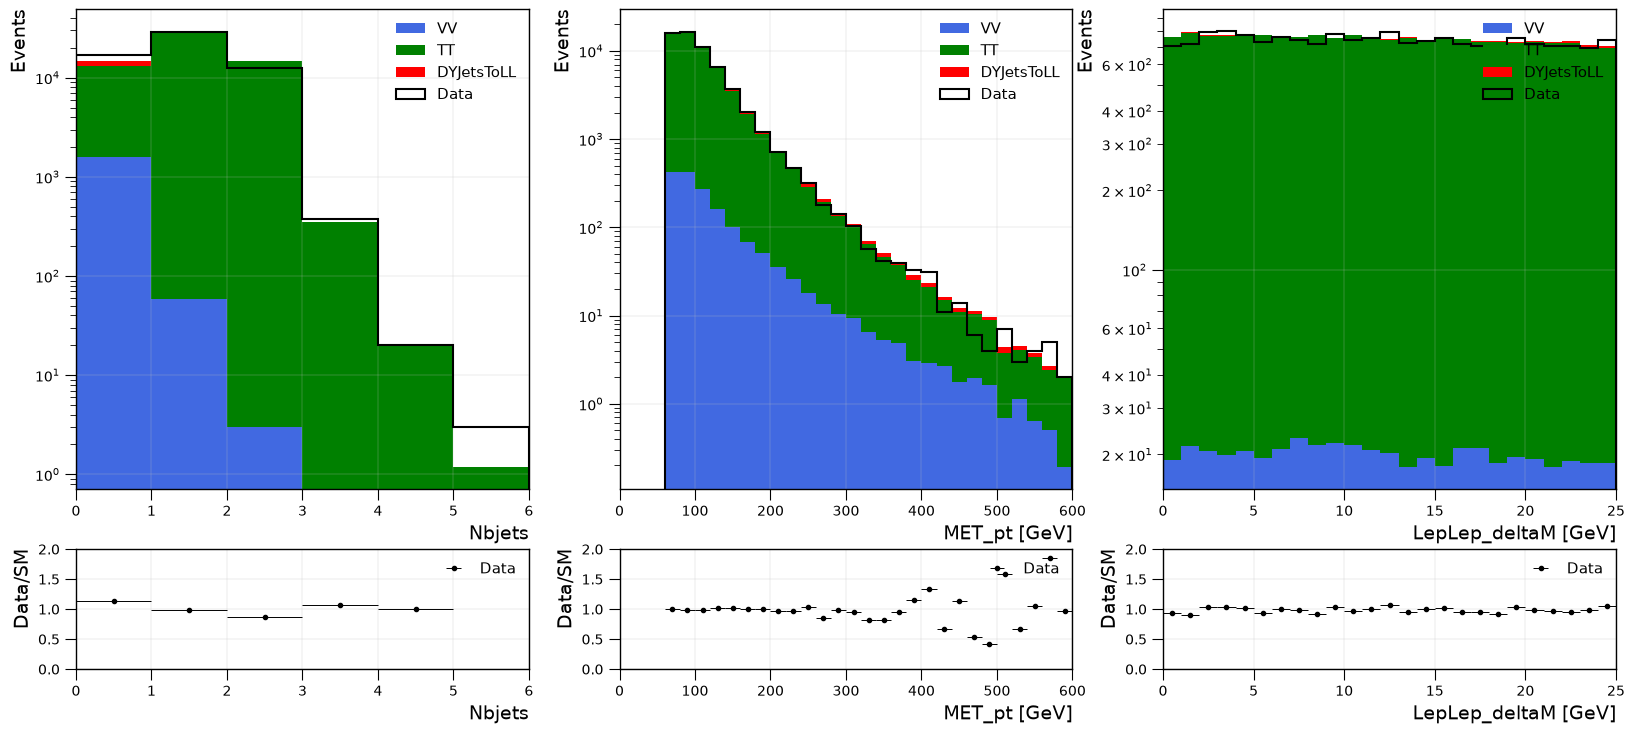

In [5]:
# Cria uma cópia dos dados brutos para aplicarmos os filtros e cortes sem perder o original
df = ds.copy()

# ==========================================
# APLICAÇÃO DOS CORTES DE SELEÇÃO FÍSICA
# ==========================================
for process in df.keys(): 
    if process != "Data":
        # Para as simulações de Monte Carlo, aplicamos o filtro de trigger do canal (HLT_EleMu),
        # a identificação dos léptons (RecoLepID > 100 para elétron + múon),
        # a energia transversal em falta (MET_pt > 65), o momento do par de léptons (LepLep_pt > 40)
        # e a exigência de pelo menos um jato (Njets >= 1).
        df[process] = df[process][
            (df[process]["HLT_EleMu"] == True) & 
            (df[process]["RecoLepID"] > 100) & 
            (df[process]["MET_pt"] > 65.0) & 
            (df[process]["LepLep_pt"] > 40.0) & 
            (df[process]["Njets"] >= 1)
        ]
    else:
        # Para os dados reais do detector, aplicamos exatamente os mesmos cortes físicos.
        # (Nota: Os dados não utilizam o fator evtWeight pois já representam as colisões reais).
        df[process] = df[process][
            (df[process]["HLT_EleMu"] == True) & 
            (df[process]["RecoLepID"] > 100) & 
            (df[process]["MET_pt"] > 65.0) & 
            (df[process]["LepLep_pt"] > 40.0) & 
            (df[process]["Njets"] >= 1)
        ]

# ==========================================
# CONFIGURAÇÃO DA FIGURA E DOS PAINÉIS
# ==========================================
# Cria uma figura grande dividida em 2 linhas e 3 colunas.
# A proporção das alturas (height_ratios) deixa o gráfico principal maior (4 partes) 
# e a razão Data/SM menor na parte de baixo (1 parte).
fig1 = plt.figure(figsize=(20,7.5))
grid = [2, 3]
gs1 = gs.GridSpec(grid[0], grid[1], height_ratios=[4, 1])

# ==========================================
# 1º GRUPO: VARIÁVEL "Nbjets" (Número de b-jatos)
# ==========================================
ax1 = plt.subplot(gs1[0])
var = "Nbjets"
bins = np.linspace(0.,6,7)
SM_values = [df["VV"][var], df["TT"][var], df["DYJetsToLL"][var]]
SM_weights = [df["VV"]["evtWeight"], df["TT"]["evtWeight"], df["DYJetsToLL"]["evtWeight"]]
SM_labels = ["VV", "TT", "DYJetsToLL"]
SM_colors = ['royalblue', 'green', "red"]

# Plota os histogramas empilhados (stacked=True) da simulação (Modelo Padrão)
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
# Plota os dados reais como uma linha preta em forma de escada (step)
Data_hist, b_dummy, p_dummy = plt.hist( df["Data"][var], bins=bins, linewidth=1.5, label='Data', color='black', histtype="step" )
plt.yscale("log") # Escala logarítmica para melhor visualização
style(ax1)
labels( ax1, xlabel="Nbjets", ylabel="Events")

# Painel inferior: Razão entre os Dados Reais e o Modelo Padrão (Data / SM)
ax1 = plt.subplot(gs1[3])
ratio = np.divide(Data_hist, SM_hist[-1], out=np.zeros_like(Data_hist, dtype=float)+9999999, where=SM_hist[-1] != 0)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, fmt='.', ecolor='black', color='black', elinewidth=0.7, capsize=0, label="Data")
plt.ylim(0., 2.0)
style(ax1)
labels( ax1, xlabel="Nbjets", ylabel="Data/SM")

# ==========================================
# 2º GRUPO: VARIÁVEL "MET_pt" (Energia Transversal em Falta)
# ==========================================
ax1 = plt.subplot(gs1[1])
var = "MET_pt"
bins = np.linspace(0.,600,31)
SM_values = [df["VV"][var], df["TT"][var], df["DYJetsToLL"][var]]
SM_weights = [df["VV"]["evtWeight"], df["TT"]["evtWeight"], df["DYJetsToLL"]["evtWeight"]]
SM_labels = ["VV", "TT", "DYJetsToLL"]
SM_colors = ['royalblue', 'green', "red"]

SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
Data_hist, b_dummy, p_dummy = plt.hist( df["Data"][var], bins=bins, linewidth=1.5, label='Data', color='black', histtype="step" )
plt.yscale("log")
style(ax1)
labels( ax1, xlabel="MET_pt [GeV]", ylabel="Events")

ax1 = plt.subplot(gs1[4])
ratio = np.divide(Data_hist, SM_hist[-1], out=np.zeros_like(Data_hist, dtype=float)+9999999, where=SM_hist[-1] != 0)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, fmt='.', ecolor='black', color='black', elinewidth=0.7, capsize=0, label="Data")
plt.ylim(0., 2.0)
style(ax1)
labels( ax1, xlabel="MET_pt [GeV]", ylabel="Data/SM")

# ==========================================
# 3º GRUPO: VARIÁVEL "LepLep_deltaM" (Diferença de Massa do Bóson Z)
# ==========================================
ax1 = plt.subplot(gs1[2])
var = "LepLep_deltaM"
bins = np.linspace(0.,25,26)
SM_values = [df["VV"][var], df["TT"][var], df["DYJetsToLL"][var]]
SM_weights = [df["VV"]["evtWeight"], df["TT"]["evtWeight"], df["DYJetsToLL"]["evtWeight"]]
SM_labels = ["VV", "TT", "DYJetsToLL"]
SM_colors = ['royalblue', 'green', "red"]

SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
Data_hist, b_dummy, p_dummy = plt.hist( df["Data"][var], bins=bins, linewidth=1.5, label='Data', color='black', histtype="step" )
plt.yscale("log")
style(ax1)
labels( ax1, xlabel="LepLep_deltaM [GeV]", ylabel="Events")

ax1 = plt.subplot(gs1[5])
ratio = np.divide(Data_hist, SM_hist[-1], out=np.zeros_like(Data_hist, dtype=float)+9999999, where=SM_hist[-1] != 0)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, fmt='.', ecolor='black', color='black', elinewidth=0.7, capsize=0, label="Data")
plt.ylim(0., 2.0)
style(ax1)
labels( ax1, xlabel="LepLep_deltaM [GeV]", ylabel="Data/SM")

# ==========================================
# AJUSTES FINAIS E SALVAMENTO DOS ARQUIVOS
# ==========================================
plt.subplots_adjust(left=0.2, bottom=0.085, right=0.97, top=0.965, wspace=0.2, hspace=0.2)
plt.savefig('variable_plots.pdf')
plt.savefig('variable_plots.png', dpi=400)

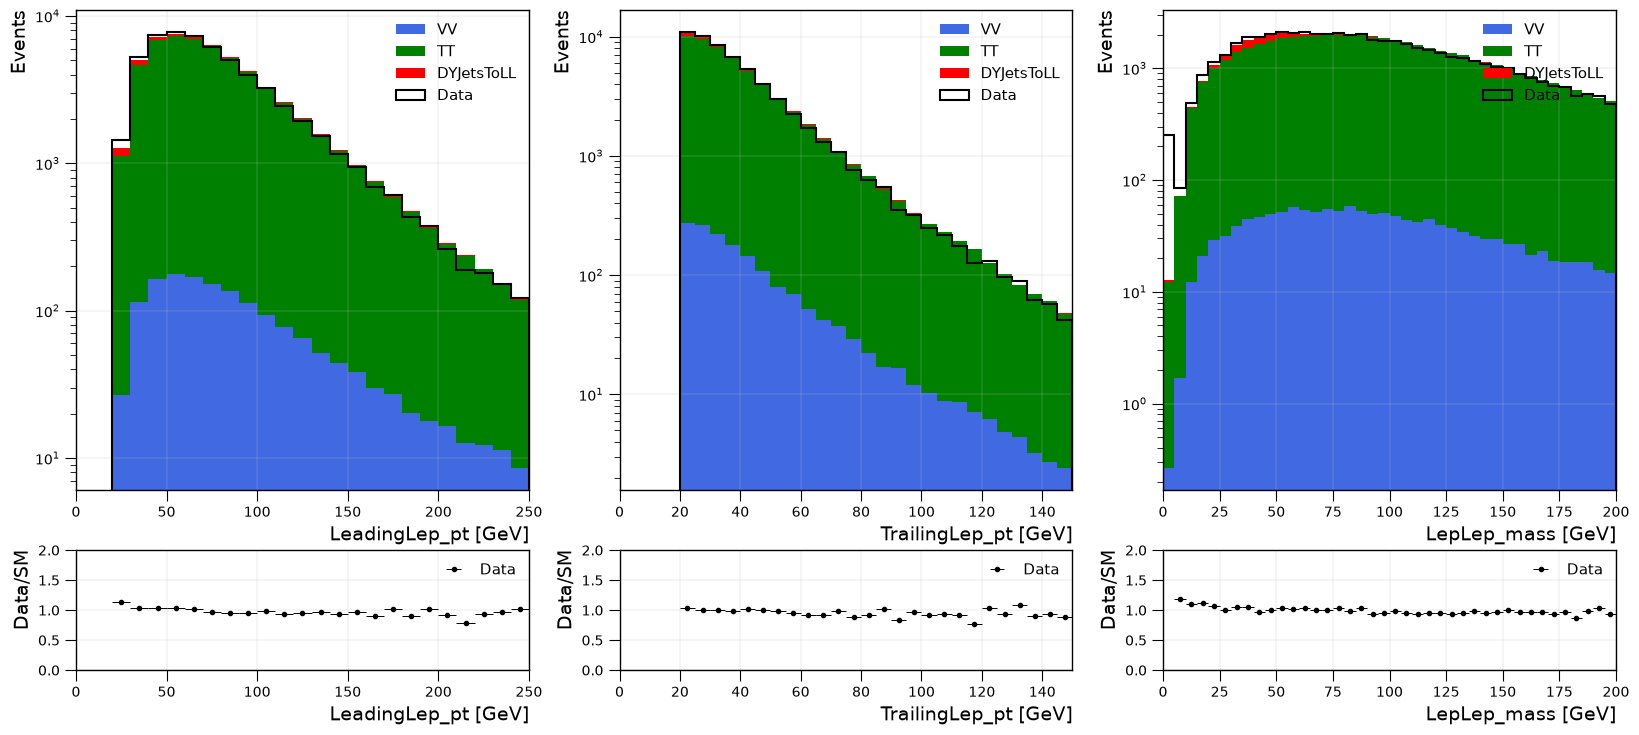

In [6]:
# Cria uma cópia dos dados brutos para aplicarmos os filtros e cortes sem perder o original
df = ds.copy()

# ==========================================
# APLICAÇÃO DOS CORTES DE SELEÇÃO FÍSICA
# ==========================================
for process in df.keys(): 
    if process != "Data":
        # Para as simulações de Monte Carlo, aplicamos o filtro de trigger do canal (HLT_EleMu),
        # a identificação dos léptons (RecoLepID > 100 para elétron + múon),
        # a energia transversal em falta (MET_pt > 65), o momento do par de léptons (LepLep_pt > 40)
        # e a exigência de pelo menos um jato (Njets >= 1).
        df[process] = df[process][
            (df[process]["HLT_EleMu"] == True) & 
            (df[process]["RecoLepID"] > 100) & 
            (df[process]["MET_pt"] > 65.0) & 
            (df[process]["LepLep_pt"] > 40.0) & 
            (df[process]["Njets"] >= 1)
        ]
    else:
        # Para os dados reais do detector, aplicamos exatamente os mesmos cortes físicos.
        # (Nota: Os dados não utilizam o fator evtWeight pois já representam as colisões reais).
        df[process] = df[process][
            (df[process]["HLT_EleMu"] == True) & 
            (df[process]["RecoLepID"] > 100) & 
            (df[process]["MET_pt"] > 65.0) & 
            (df[process]["LepLep_pt"] > 40.0) & 
            (df[process]["Njets"] >= 1)
        ]

# ==========================================
# CONFIGURAÇÃO DA FIGURA E DOS PAINÉIS
# ==========================================
# Cria uma figura grande dividida em 2 linhas e 3 colunas.
# A proporção das alturas (height_ratios) deixa o gráfico principal maior (4 partes) 
# e a razão Data/SM menor na parte de baixo (1 parte).
fig1 = plt.figure(figsize=(20,7.5))
grid = [2, 3]
gs1 = gs.GridSpec(grid[0], grid[1], height_ratios=[4, 1])

# ==========================================
# 1º GRUPO: VARIÁVEL "LeadingLep_pt" (Momento Transversal do Lépton Principal)
# ==========================================
ax1 = plt.subplot(gs1[0])
var = "LeadingLep_pt"
bins = np.linspace(0.,250,26)
SM_values = [df["VV"][var], df["TT"][var], df["DYJetsToLL"][var]]
SM_weights = [df["VV"]["evtWeight"], df["TT"]["evtWeight"], df["DYJetsToLL"]["evtWeight"]]
SM_labels = ["VV", "TT", "DYJetsToLL"]
SM_colors = ['royalblue', 'green', "red"]

# Plota os histogramas empilhados (stacked=True) da simulação (Modelo Padrão)
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
# Plota os dados reais como uma linha preta em forma de escada (step)
Data_hist, b_dummy, p_dummy = plt.hist( df["Data"][var], bins=bins, linewidth=1.5, label='Data', color='black', histtype="step" )
plt.yscale("log") # Escala logarítmica para melhor visualização
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Events")

# Painel inferior: Razão entre os Dados Reais e o Modelo Padrão (Data / SM)
ax1 = plt.subplot(gs1[3])
ratio = np.divide(Data_hist, SM_hist[-1], out=np.zeros_like(Data_hist, dtype=float)+9999999, where=SM_hist[-1] != 0)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, fmt='.', ecolor='black', color='black', elinewidth=0.7, capsize=0, label="Data")
plt.ylim(0., 2.0)
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Data/SM")

# ==========================================
# 2º GRUPO: VARIÁVEL "TrailingLep_pt" (Momento Transversal do Lépton Secundário)
# ==========================================
ax1 = plt.subplot(gs1[1])
var = "TrailingLep_pt"
bins = np.linspace(0.,150,31)
SM_values = [df["VV"][var], df["TT"][var], df["DYJetsToLL"][var]]
SM_weights = [df["VV"]["evtWeight"], df["TT"]["evtWeight"], df["DYJetsToLL"]["evtWeight"]]
SM_labels = ["VV", "TT", "DYJetsToLL"]
SM_colors = ['royalblue', 'green', "red"]

SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
Data_hist, b_dummy, p_dummy = plt.hist( df["Data"][var], bins=bins, linewidth=1.5, label='Data', color='black', histtype="step" )
plt.yscale("log")
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Events")

ax1 = plt.subplot(gs1[4])
ratio = np.divide(Data_hist, SM_hist[-1], out=np.zeros_like(Data_hist, dtype=float)+9999999, where=SM_hist[-1] != 0)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, fmt='.', ecolor='black', color='black', elinewidth=0.7, capsize=0, label="Data")
plt.ylim(0., 2.0)
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Data/SM")

# ==========================================
# 3º GRUPO: VARIÁVEL "LepLep_mass" (Massa Invariante do Par de Léptons)
# ==========================================
ax1 = plt.subplot(gs1[2])
var = "LepLep_mass"
bins = np.linspace(0.,200,41)
SM_values = [df["VV"][var], df["TT"][var], df["DYJetsToLL"][var]]
SM_weights = [df["VV"]["evtWeight"], df["TT"]["evtWeight"], df["DYJetsToLL"]["evtWeight"]]
SM_labels = ["VV", "TT", "DYJetsToLL"]
SM_colors = ['royalblue', 'green', "red"]

SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
Data_hist, b_dummy, p_dummy = plt.hist( df["Data"][var], bins=bins, linewidth=1.5, label='Data', color='black', histtype="step" )
plt.yscale("log")
style(ax1)
labels( ax1, xlabel="LepLep_mass [GeV]", ylabel="Events")

ax1 = plt.subplot(gs1[5])
ratio = np.divide(Data_hist, SM_hist[-1], out=np.zeros_like(Data_hist, dtype=float)+9999999, where=SM_hist[-1] != 0)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, fmt='.', ecolor='black', color='black', elinewidth=0.7, capsize=0, label="Data")
plt.ylim(0., 2.0)
style(ax1)
labels( ax1, xlabel="LepLep_mass [GeV]", ylabel="Data/SM")

# ==========================================
# AJUSTES FINAIS E SALVAMENTO DOS ARQUIVOS
# ==========================================
plt.subplots_adjust(left=0.2, bottom=0.085, right=0.97, top=0.965, wspace=0.2, hspace=0.2)
plt.savefig('variable_plots_improved2.pdf')
plt.savefig('variable_plots_improved2.png', dpi=400)